## Analysis of time course data

First run the sorting and calibration scripts

In [20]:
from chromhandler import Handler, Molecule, Protein, to_enzymeml
from pathlib import Path
import numpy as np
from utility import plot_replicates

# create list to add molecules to
molecules = []

# define path to the calibration molecules
molecule_dir = Path("Results/Molecules/")

# loop over all the json files in the calibration molecules folder
# and create molecule objects
for molecule_path in molecule_dir.glob("*.json"):
    molecule = Molecule.read_json(molecule_path)
    molecules.append(molecule)

    if molecule.id == "cGAMP":
        molecule.retention_time = 2.56
        molecule.retention_tolerance = 0.07
    
    if molecule.id == "ADP":
        molecule.retention_time = 2.65
        molecule.retention_tolerance = 0.07

    if molecule.id == "GDP":
        molecule.retention_time = 3.67
        molecule.retention_tolerance = 0.1

    if molecule.id == "ATP":
        molecule.retention_time = 4.77
        molecule.retention_tolerance = 0.1

    if molecule.id == "GTP":
        molecule.retention_time = 6.79
        molecule.retention_tolerance = 0.3

print(f"Loaded {len(molecules)} with IDs {[m.id for m in molecules]}")


Loaded 8 with IDs ['ADP', 'ATP', 'cGAMP', 'GDP', 'GTP', 'HEPES', 'MgCl2', 'TrisHCl']


## Load proteins

In [21]:
proteins = []

for protein_path in Path("Results/Proteins").glob("*.json"):
    protein = Protein.read_json(protein_path)
    proteins.append(protein)

print(f"Loaded {len(proteins)} with names {[p.name for p in proteins]}")

Loaded 2 with names ['thscGAS', 'tmmcGAS']


## Load metadata (from excel sheet)

In [23]:

# # load metadata as dataframe
# metadata_path = "Input/metadata_tmmcGAS.xlsx"
# metadata_df = pd.read_excel(metadata_path)

# # set 'experiment_name' as index
# metadata_df.set_index("experiment_name", inplace=True)

# metadata_df

# ### few code lines to make replicates = conditions

import pandas as pd
from pathlib import Path

metadata_path = "Input/metadata.xlsx"
conditions = pd.read_excel(metadata_path).set_index("experiment_name")

# strip units from headers: "tmmcGAS [mg/mL]" -> "tmmcGAS"
conditions.columns = (conditions.columns
                      .str.replace(r"\s*[\[\(].*?[\]\)]", "", regex=True)
                      .str.strip())

# empty cell = 0 everywhere
conditions = conditions.fillna(0)

# proteins: mg/mL in the table -> µmol/L for the analyzer
MW = {"tmmcGAS": 55933, "thscGAS": 55872}   # g/mol, FILL IN for your constructs
for protein_id, mw in MW.items():
    conditions[protein_id] = conditions[protein_id] / mw * 1e6


# the calibration can't take an exact 0 for a homolog, so 0 -> tiny value
conditions[list(MW)] = conditions[list(MW)].replace(0, 1e-8)

# replicates share their condition's metadata: X -> X_1, X_2, X_3
REPLICATES = [1, 2, 3]
metadata_df = pd.concat(
    conditions.rename(index=lambda name: f"{name}_{r}") for r in REPLICATES
).sort_index()

metadata_df



,reaction_vol,temperature,pH,HEPES,TrisHCl,MgCl2,tmmcGAS,thscGAS,ATP,GTP,cGAMP,ADP,GDP
experiment_name,,,,,,,,,,,,,
20251117_100mM-HEPES_0.02-tmmcGAS_1,1,37,7.2,100,0,10,0.357571,1.000000e-08,0.5,0.5,0,0,0
20251117_100mM-HEPES_0.02-tmmcGAS_2,1,37,7.2,100,0,10,0.357571,1.000000e-08,0.5,0.5,0,0,0
20251117_100mM-HEPES_0.02-tmmcGAS_3,1,37,7.2,100,0,10,0.357571,1.000000e-08,0.5,0.5,0,0,0
20260520_100mM-HEPES_0.04_tmmcGAS_1,1,37,7.0,100,0,10,0.715141,1.000000e-08,0.5,0.5,0,0,0
20260520_100mM-HEPES_0.04_tmmcGAS_2,1,37,7.0,100,0,10,0.715141,1.000000e-08,0.5,0.5,0,0,0
20260520_100mM-HEPES_0.04_tmmcGAS_3,1,37,7.0,100,0,10,0.715141,1.000000e-08,0.5,0.5,0,0,0


## Process time-course data

In [24]:
sample_dir = Path("Data/time_sample/20260520_100mM-HEPES_0.04_tmmcGAS") # CHANGE HERE #

# loop over all the time samples and create the ChromAnalyzer objects
handlers = []
for time_samples in sample_dir.iterdir():
    run = str(time_samples.name)
    analyzer = Handler.read_agilent(
        path=str(time_samples),
        ph=metadata_df.loc[run, "pH"],
        temperature=metadata_df.loc[run, "temperature"],
        mode="timecourse",
    )

    # add molecule data to the analyzer (table is in mM)
    for molecule in molecules:
        # missing column in the table = 0
        init_conc = metadata_df.loc[run].get(molecule.id, 0.0)

        # set constant molecules (concentration does not change over time)
        if molecule.id in ["MgCl2", "HEPES", "TrisHCl"]: # Add molecules here # CHANGE HERE #
            molecule.constant = True

        if not np.isnan(init_conc):
            analyzer.add_molecule(molecule, init_conc=init_conc, conc_unit="mmol / L")

    #analyzer.visualize(rt_min = 5.4, rt_max = 5.8 ) Looks for ATP peak

    # add protein data to the analyzer (converted to µM in the metadata cell)
    for protein in proteins:
        init_conc = metadata_df.loc[run].get(protein.name, 0.0)

        if not np.isnan(init_conc):
            analyzer.add_protein(protein, init_conc=init_conc, conc_unit="umol / L")

    analyzer.assign_all_peaks()

    handlers.append(analyzer)

               🎯 Peak Assignment Summary of                
            20260520_100mM-HEPES_0.04_tmmcGAS_1             
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ Molecule             ┃   Status   ┃ Details              ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ ADP (ADP)            │ ⚠️ Overlaps │ (7/7) peaks assigned │
│ ATP (ATP)            │ ✅ Success │ (7/7) peaks assigned │
│ cGAMP (cGAMP)        │ ✅ Success │ (7/7) peaks assigned │
│ GDP (GDP)            │ 🟡 Partial │ (6/7) peaks assigned │
│ GTP (GTP)            │ ⚠️ Overlaps │ (5/7) peaks assigned │
└──────────────────────┴────────────┴──────────────────────┘

               🎯 Peak Assignment Summary of                
            20260520_100mM-HEPES_0.04_tmmcGAS_2             
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ Molecule             ┃   Status   ┃ Details              ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ ADP (ADP)            │ ⚠️ Overlaps │ (7/7) peaks assigned │
│ ATP (ATP)            │ ✅ Success │ (7/7) peaks assigned │
│ cGAMP (cGAMP)        │ ✅ Success │ (7/7) peaks assigned │
│ GDP (GDP)            │ 🟡 Partial │ (6/7) peaks assigned │
│ GTP (GTP)            │ ⚠️ Overlaps │ (5/7) peaks assigned │
└──────────────────────┴────────────┴──────────────────────┘

               🎯 Peak Assignment Summary of                
            20260520_100mM-HEPES_0.04_tmmcGAS_3             
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ Molecule             ┃   Status   ┃ Details              ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ ADP (ADP)            │ ⚠️ Overlaps │ (7/7) peaks assigned │
│ ATP (ATP)            │ 🟡 Partial │ (6/7) peaks assigned │
│ cGAMP (cGAMP)        │ ✅ Success │ (7/7) peaks assigned │
│ GDP (GDP)            │ ✅ Success │ (7/7) peaks assigned │
│ GTP (GTP)            │ ⚠️ Overlaps │ (7/7) peaks assigned │
└──────────────────────┴────────────┴──────────────────────┘

## Create EnzymeML document with replicates

In [25]:
import pyenzyme as pe #reads, write, and modify enzymeML doc.

# add the metadata to the timecourse data
timecourse_enzymeML = to_enzymeml(
    document_name=sample_dir.name, # uses the folder name e.g. "20260520_100mM-HEPES_0.04_tmmcGAS"
    handlers=handlers,
    calculate_concentration=True,
    extrapolate=False,
)

# add vessel
vessel = pe.Vessel(
    id="v1",
    name="Eppendorf Tube",
    volume="1",
    unit="ml",
)
timecourse_enzymeML.vessels = [vessel]

# identify replicates
timecourse_enzymeML = pe.group_measurements(timecourse_enzymeML, attribute="prepared")

# show summary of document
pe.summary(timecourse_enzymeML)

# save the enzymeML document to file
pe.write_enzymeml(
    timecourse_enzymeML, f"Results/enzymeML/{timecourse_enzymeML.name}.json"
)

📋 EnzymeML Document Summary

╭─ 📄 Document Overview ──────────────────────────────────────────────────────────────────────────────────────────╮
│ Name: 20260520_100mM-HEPES_0.04_tmmcGAS                                                                         │
│ Version: 2.1                                                                                                    │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

    📊 Component Counts                                                                   
┏━━━━━━━━━━━━━━━━━┳━━━━━━━┓                                                               
┃ Component       ┃ Count ┃                                                               
┡━━━━━━━━━━━━━━━━━╇━━━━━━━┩                                                               
│ Vessels         │     1 │                                                               
│ Proteins        │     2 │                                                               
│ Complexes       │     0 │                                                               
│ Small Molecules │     8 │                                                               
│ Reactions       │     0 │                                                               
│ Measurements    │     3 │                                                               
│ Equations       │     0 │                                                               
│ Parameters      │     0 │                                                               
└─────────────────┴───────┘                                                               
                                    🧬 Species Details                                    
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Type           ┃ ID                    ┃ Name                 ┃ Details                ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Protein        │ Q8N884                │ thscGAS              │ Organism: Homo sapiens │
│ Protein        │ Q8C6L5                │ tmmcGAS              │ Organism: Mus musculus │
│ Small Molecule │ ADP                   │ ADP                  │ —                      │
│ Small Molecule │ ATP                   │ ATP                  │ —                      │
│ Small Molecule │ cGAMP                 │ cGAMP                │ —                      │
│ Small Molecule │ GDP                   │ GDP                  │ —                      │
│ Small Molecule │ GTP                   │ GTP                  │ —                      │
│                │ ... +3 more molecules │                      │                        │
└────────────────┴───────────────────────┴──────────────────────┴────────────────────────┘

                🧪 Vessels                 
┏━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┓
┃ ID ┃ Name           ┃ Volume ┃ Constant ┃
┡━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━┩
│ v1 │ Eppendorf Tube │ 1.0 ml │    ✓     │
└────┴────────────────┴────────┴──────────┘

                                                  📈 Measurements                                                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ ID                                ┃ Name                               ┃ Species Data ┃ Conditions              ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 20260520_100mM-HEPES_0.04_tmmcGA… │ 20260520_100mM-HEPES_0.04_tmmcGAS… │      10      │ pH: 7.0 | T: 37.0 deg_C │
│ 20260520_100mM-HEPES_0.04_tmmcGA… │ 20260520_100mM-HEPES_0.04_tmmcGAS… │      10      │ pH: 7.0 | T: 37.0 deg_C │
│ 20260520_100mM-HEPES_0.04_tmmcGA… │ 20260520_100mM-HEPES_0.04_tmmcGAS… │      10      │ pH: 7.0 | T: 37.0 deg_C │
└───────────────────────────────────┴────────────────────────────────────┴──────────────┴───────

EnzymeML document written to Results\enzymeML\20260520_100mM-HEPES_0.04_tmmcGAS.json

## Plot

Color and axis can be changed in enzml_broken_axis.py in the input folder


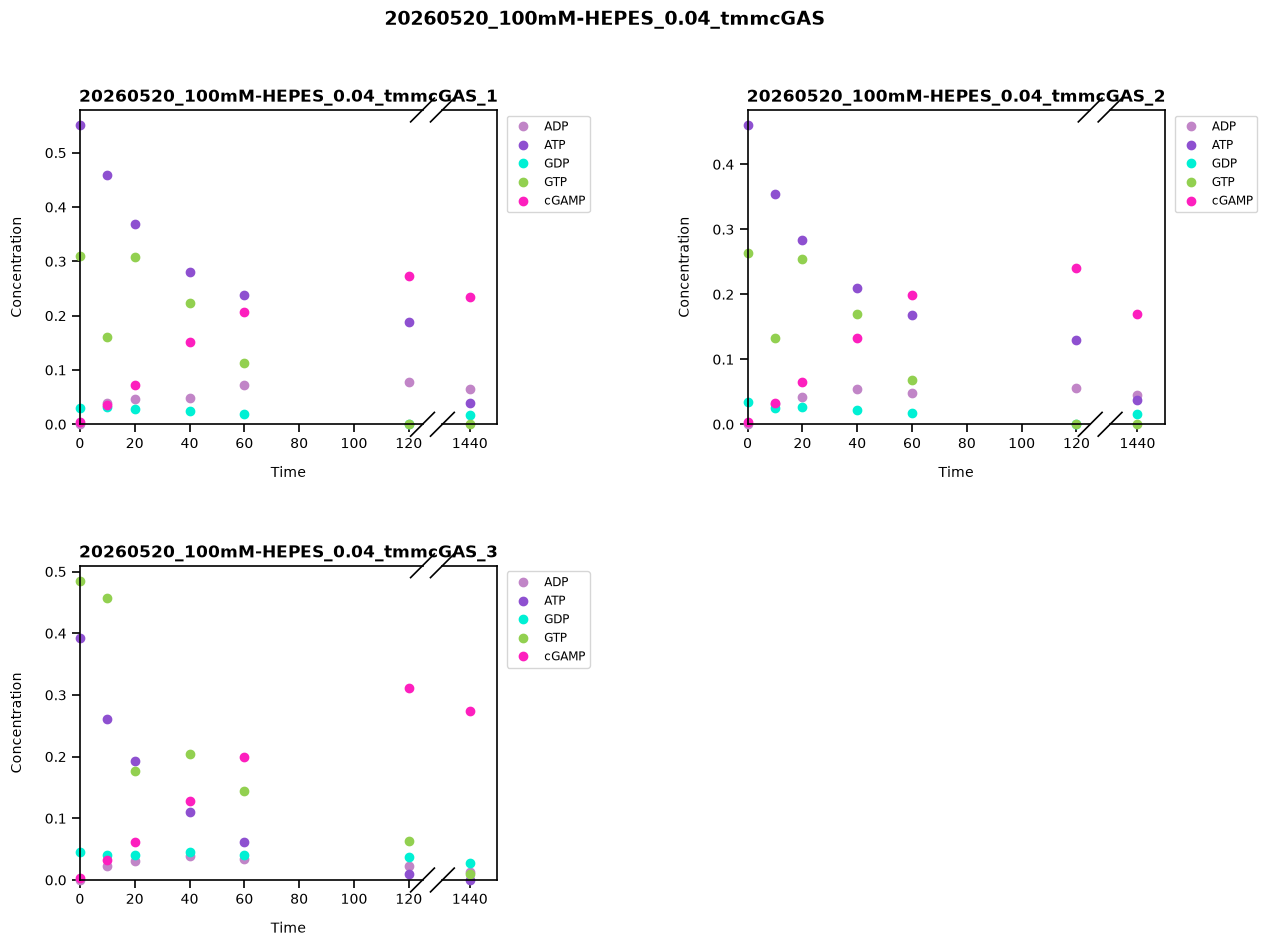

In [26]:
import sys
sys.path.append("Input")

# If you want to change the plots layout, open broken_closed_frame_axis.py (in Input folder), and change there! 
from broken_open_frame_axis import to_broken_axes

fig, ax = pe.plot(timecourse_enzymeML)
bfig, baxes = to_broken_axes(ax, doc=timecourse_enzymeML)


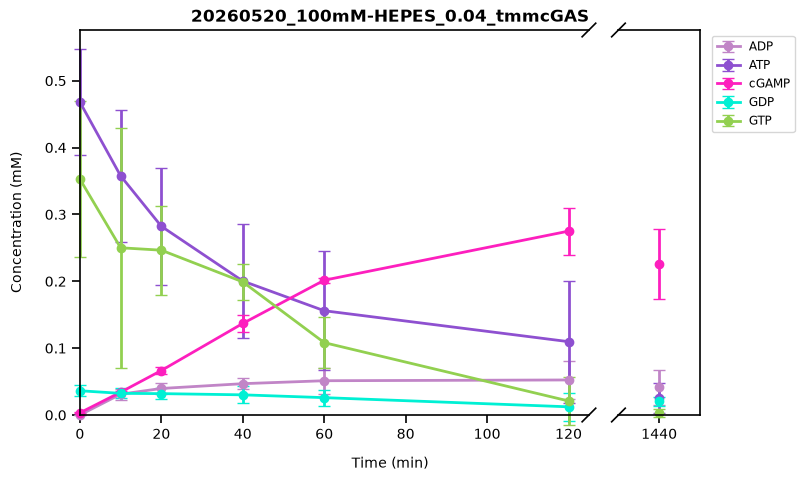

In [27]:
import sys, importlib
sys.path.append("Input")

# Closed frames around both broken axis parts
# import broken_closed_frame_axis
# importlib.reload(broken_closed_frame_axis)
# from enzml_broken_axis import plot_replicates

# Only closed frame around the plot 
import broken_open_frame_axis
importlib.reload(broken_open_frame_axis)
from broken_open_frame_axis import plot_replicates

#fig_all, _  = plot_replicates(timecourse_enzymeML)
fig_mean, _ = plot_replicates(timecourse_enzymeML, mean_sd=True)

name = timecourse_enzymeML.name

#fig_all.savefig(f"Results/{name}_replicates_broken.png", dpi=300, bbox_inches="tight")
fig_mean.savefig(f"Results/{name}_replicates_mean_sd_broken.png", dpi=300, bbox_inches="tight")